# Setup and data exploration
**Project:** Modeling day to day physiological recovery from consumer wearables (LifeSnaps)
**Author:** Maitrey Phatak

This notebook (1) verifies the environment, (2) loads the LifeSnaps CSVs, and (3) runs the data audit
that defines the analysis cohort: participants, collection windows, mood label counts, signal coverage,
and the carry forward baseline.

## 1. Environment check

In [1]:
import sys, platform
import numpy as np, pandas as pd, scipy, sklearn, matplotlib
import matplotlib.pyplot as plt
print('Python', sys.version.split()[0], '|', platform.system())
for m in [np, pd, scipy, sklearn, matplotlib]:
    print(f'{m.__name__:12s} {m.__version__}')

Python 3.13.18 | Linux
numpy        2.5.3
pandas       3.0.5
scipy        1.18.1
sklearn      1.9.1
matplotlib   3.11.2


## 2. Load the data
Files come from LifeSnaps version 4 (Zenodo DOI 10.5281/zenodo.7229547, CC BY 4.0). See `data/README.md`.

In [2]:
RAW = '../data/raw/'
MOOD = ['ALERT','HAPPY','NEUTRAL','RESTED/RELAXED','SAD','TENSE/ANXIOUS','TIRED']
daily = pd.read_csv(RAW + 'daily_fitbit_sema_df_unprocessed.csv', low_memory=False)
hourly = pd.read_csv(RAW + 'hourly_fitbit_sema_df_unprocessed.csv', low_memory=False,
                     usecols=['id','date','hour','bpm','steps'] + MOOD)
pers = pd.read_csv(RAW + 'personality.csv')
daily['date'] = pd.to_datetime(daily['date']); hourly['date'] = pd.to_datetime(hourly['date'])
print('daily      ', daily.shape)
print('hourly     ', hourly.shape)
print('personality', pers.shape)
daily[['id','date','minutesAsleep','sleep_efficiency','resting_hr','rmssd','steps'] + MOOD].head()

daily       (7410, 63)
hourly      (159508, 12)
personality (50, 15)


,id,date,minutesAsleep,sleep_efficiency,resting_hr,rmssd,steps,ALERT,HAPPY,NEUTRAL,RESTED/RELAXED,SAD,TENSE/ANXIOUS,TIRED
0,621e2e8e67b776a24055b564,2021-05-24,445.0,93.0,62.073070,89.603,8833.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,621e2e8e67b776a24055b564,2021-05-25,460.0,94.0,62.121476,94.303,9727.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,621e2e8e67b776a24055b564,2021-05-26,493.0,96.0,62.263999,119.212,8253.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,621e2e8e67b776a24055b564,2021-05-27,540.0,93.0,62.368900,111.709,9015.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,621e2e8e67b776a24055b564,2021-05-28,493.0,94.0,61.965409,103.034,12949.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


## 3. Participants and collection windows
The dataset title says 4 months; the per person mood reporting window is about 8 weeks.

In [3]:
g = daily.groupby('id')
fitbit = daily[daily.steps.notna() | daily.resting_hr.notna()].groupby('id').date
ema = daily[daily[MOOD].notna().all(axis=1)].groupby('id').date
summary = pd.DataFrame({
    'Fitbit span (days)': (fitbit.max() - fitbit.min()).dt.days + 1,
    'Mood reporting span (days)': (ema.max() - ema.min()).dt.days + 1})
print('participants:', daily.id.nunique(), '| dates', daily.date.min().date(), 'to', daily.date.max().date())
print('cohort start month counts:', g.date.min().dt.to_period('M').value_counts().sort_index().to_dict())
summary.describe().round(1)

participants: 71 | dates 2021-04-08 to 2022-01-22
cohort start month counts: {Period('2021-04', 'M'): 2, Period('2021-05', 'M'): 42, Period('2021-06', 'M'): 2, Period('2021-10', 'M'): 12, Period('2021-11', 'M'): 13}


,Fitbit span (days),Mood reporting span (days)
count,71.0,63.0
mean,76.3,48.5
std,45.3,28.9
min,1.0,1.0
25%,62.5,28.0
50%,67.0,57.0
75%,86.0,62.5
max,244.0,193.0


## 4. Mood label audit
Each mood report selects one category. The hourly file holds the individual reports.

In [4]:
lab_days = daily[daily[MOOD].notna().all(axis=1)].groupby('id').size()
print('people with any mood data:', len(lab_days), '| labeled days:', lab_days.sum(), '| median per person:', lab_days.median())
pd.DataFrame({'minimum labeled days': [7,14,21,28,42],
              'people remaining': [(lab_days >= t).sum() for t in [7,14,21,28,42]]})

people with any mood data: 63 | labeled days: 2290 | median per person: 40.0


,minimum labeled days,people remaining
0,7,52
1,14,48
2,21,41
3,28,36
4,42,30


analysis cohort (>= 14 labeled days): 48 people, 4912 mood reports


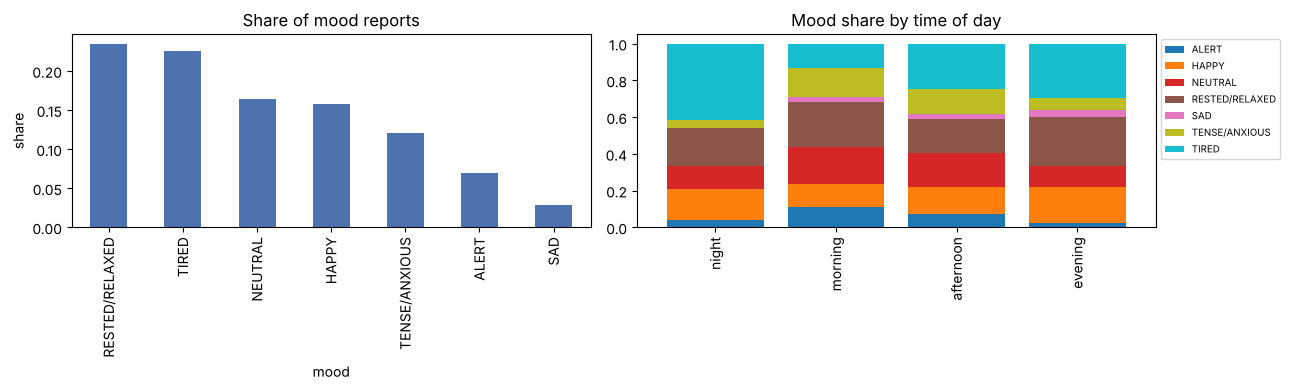

In [5]:
cohort = lab_days[lab_days >= 14].index
rep = hourly[hourly.id.isin(cohort) & hourly[MOOD].notna().all(axis=1)].copy()
rep['mood'] = rep[MOOD].idxmax(axis=1)
rep['slot'] = pd.cut(rep.hour, [-1,5,13,18,24], labels=['night','morning','afternoon','evening'])
print('analysis cohort (>= 14 labeled days):', len(cohort), 'people,', len(rep), 'mood reports')
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
rep.mood.value_counts(normalize=True).plot.bar(ax=ax[0], color='#4C72B0')
ax[0].set_title('Share of mood reports'); ax[0].set_ylabel('share')
pd.crosstab(rep.slot, rep.mood, normalize='index').plot.bar(stacked=True, ax=ax[1], colormap='tab10', width=.8)
ax[1].set_title('Mood share by time of day'); ax[1].legend(fontsize=7, bbox_to_anchor=(1, 1)); ax[1].set_xlabel('')
plt.tight_layout(); plt.show()

## 5. Signal coverage on mood labeled days (analysis cohort)

In [6]:
lab = daily[daily.id.isin(cohort) & daily[MOOD].notna().all(axis=1)].copy()
lab.loc[lab.rmssd <= 0, 'rmssd'] = np.nan   # zero RMSSD is not physiological
cols = ['steps','resting_hr','minutesAsleep','nightly_temperature','rmssd','stress_score']
pd.DataFrame({'share of mood days covered': lab[cols].notna().mean().round(2),
              'people with any': [daily.loc[daily.id.isin(cohort) & daily[c].notna(), 'id'].nunique() for c in cols]})

,share of mood days covered,people with any
steps,0.91,48
resting_hr,0.87,48
minutesAsleep,0.78,47
nightly_temperature,0.76,45
rmssd,0.51,31
stress_score,0.45,27


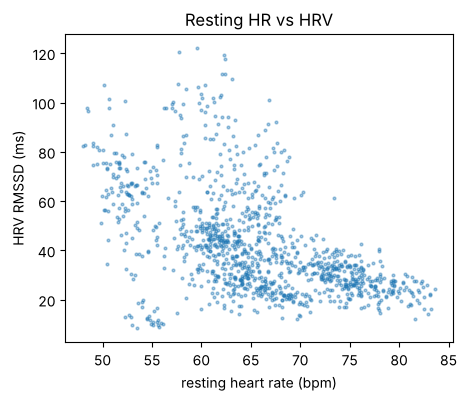

correlation: -0.518


In [7]:
x = lab[['resting_hr','rmssd']].dropna()
plt.figure(figsize=(5, 4)); plt.scatter(x.resting_hr, x.rmssd, s=4, alpha=.4)
plt.xlabel('resting heart rate (bpm)'); plt.ylabel('HRV RMSSD (ms)'); plt.title('Resting HR vs HRV')
plt.show(); print('correlation:', round(x.corr().iloc[0, 1], 3))

## 6. Carry forward baseline
Predict each report as the previous report's category (within 36 hours).

In [8]:
from sklearn.metrics import balanced_accuracy_score, f1_score
rep = rep.sort_values(['id','date','hour'])
rep['t'] = rep.date + pd.to_timedelta(rep.hour, unit='h')
rep['prev'] = rep.groupby('id').mood.shift()
rep['gap'] = (rep.t - rep.groupby('id').t.shift()).dt.total_seconds() / 3600
p = rep[rep.prev.notna() & (rep.gap <= 36)]
print('pairs:', len(p))
print('balanced accuracy:', round(balanced_accuracy_score(p.mood, p.prev), 3), '| chance:', round(1/7, 3))
print('macro F1:', round(f1_score(p.mood, p.prev, average='macro'), 3))

pairs: 4677
balanced accuracy: 0.308 | chance: 0.143
macro F1: 0.308


## 7. Personality coverage
`stability` is Big Five emotional stability (inverse of neuroticism). LifeSnaps STAI is the state version, so stability is the trait measure used.

In [9]:
print('personality available for', pers.user_id.nunique(), 'people;', pers.user_id.isin(cohort).sum(), 'are in the analysis cohort')
pers[['extraversion','agreeableness','conscientiousness','stability','intellect']].describe().round(1)

personality available for 50 people; 40 are in the analysis cohort


,extraversion,agreeableness,conscientiousness,stability,intellect
count,50.0,50.0,50.0,50.0,50.0
mean,30.1,38.3,33.4,29.8,36.6
std,8.2,6.4,6.9,8.2,5.3
min,13.0,20.0,21.0,11.0,27.0
25%,22.0,34.0,28.0,24.2,34.0
50%,31.5,39.0,33.5,31.0,36.0
75%,36.5,43.8,39.0,34.8,40.0
max,45.0,49.0,46.0,46.0,48.0


## Environment verified
All cells executed. Next: `run_all.sh` reproduces the stage 1 state space model results.